<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5a_dualcomplexos_algebra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V (a): a álgebra dos números dual-complexos

## Posição e orientação num número só: o primeiro grupo que não comuta

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 5](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb)) · **Próximo:** [X5b_dualcomplexos_sistemas.ipynb](X5b_dualcomplexos_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5b_dualcomplexos_sistemas.ipynb))

**Objetivo.** Até aqui, a série guardou a posição de um objeto (domínio II) e a orientação dele (domínios III e IV) separadamente. Este domínio junta as duas numa **pose**: onde o objeto está **e** para onde ele aponta. O conjunto das poses do plano, com a composição "fazer um movimento depois do outro", é o grupo $SE(2)$, e ele tem uma propriedade que nenhum grupo anterior tinha: **não é comutativo**. Girar e depois andar não leva ao mesmo lugar que andar e depois girar.

Os **números dual-complexos** representam uma pose por um único número, $q=a+b\,\varepsilon$, com $a$ e $b$ complexos, $\varepsilon^2=0$ e uma regra nova: $z\,\varepsilon=\varepsilon\,\bar z$ (passar um complexo pelo $\varepsilon$ o conjuga). A regra é o que torna a álgebra não comutativa, e é ela que permite representar $SE(2)$.

> **Atenção: dois objetos com o mesmo nome.** Na literatura, "números dual-complexos" designa às vezes os complexos com coeficientes duais, $a+b\varepsilon$ com $\varepsilon$ **comutando** com tudo. É uma álgebra comutativa útil para derivar funções complexas, mas **não** representa poses: os elementos invertíveis de um anel comutativo formam um grupo comutativo, e $SE(2)$ não é comutativo. A seção 1 mostra isso numericamente. Aqui, dual-complexo é sempre a álgebra não comutativa (Matsuda, Kakuta e outros, 2014, que a introduziram para animação 2D).

**Roteiro**
1. Por que um anel não comutativo
2. A álgebra: produto, conjugado, divisores de zero e a representação por matrizes
3. Poses: composição, inverso e o duplo recobrimento
4. O braço articulado: uma cadeia de poses é um produto
5. Exp e Log: arcos de círculo, o centro de rotação e uma fórmula que perde dígitos
6. Interpolar poses: o arco e a reta
7. Deformar um personagem 2D (*skinning*)
8. Poses exatas com inteiros gaussianos
9. A interface de domínio para $SE(2)$
10. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from fractions import Fraction
rng = np.random.default_rng(51)

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

class DC:
    """Número dual-complexo q = a + b·ε, com a = a0 + i·a1 e b = b0 + i·b1, e a regra z·ε = ε·z̄.
    Guardado como quatro reais (a0, a1, b0, b1), que podem ser floats, Fractions ou números duais."""
    def __init__(self, a0, a1, b0, b1):
        self.a0, self.a1, self.b0, self.b1 = a0, a1, b0, b1
    def __mul__(self, o):
        if not isinstance(o, DC):                       # número real vezes dual-complexo
            return DC(self.a0 * o, self.a1 * o, self.b0 * o, self.b1 * o)
        # a = a1·a2 ;  b = a1·b2 + b1·conj(a2)   (a regra z ε = ε z̄ conjuga o fator que "passa" por ε)
        a0 = self.a0 * o.a0 - self.a1 * o.a1
        a1 = self.a0 * o.a1 + self.a1 * o.a0
        b0 = (self.a0 * o.b0 - self.a1 * o.b1) + (self.b0 * o.a0 + self.b1 * o.a1)
        b1 = (self.a0 * o.b1 + self.a1 * o.b0) + (self.b1 * o.a0 - self.b0 * o.a1)
        return DC(a0, a1, b0, b1)
    __rmul__ = __mul__
    def __add__(self, o): return DC(self.a0 + o.a0, self.a1 + o.a1, self.b0 + o.b0, self.b1 + o.b1)
    def __sub__(self, o): return DC(self.a0 - o.a0, self.a1 - o.a1, self.b0 - o.b0, self.b1 - o.b1)
    def conj(self):
        """q* = ā − b ε: o inverso de um dual-complexo unitário."""
        return DC(self.a0, -self.a1, -self.b0, -self.b1)
    def norma2(self):
        """q q* = |a|² (um número real: a parte dual se cancela)."""
        return self.a0 * self.a0 + self.a1 * self.a1
    @property
    def a(self): return complex(self.a0, self.a1)
    @property
    def b(self): return complex(self.b0, self.b1)
    def __repr__(self): return f"({self.a:.6g}) + ({self.b:.6g})ε"

def pose(theta, t):
    """A pose 'girar θ, transladar t' (t complexo): q = r + (t r̄ / 2) ε, com r = e^{iθ/2}."""
    r = np.exp(0.5j * theta); b = t * np.conj(r) / 2
    return DC(r.real, r.imag, b.real, b.imag)

def angulo(q):
    return float(wrap(2 * np.arctan2(q.a1, q.a0)))

def translacao(q):
    """t = 2 b a / |a|² (vale também para q não unitário)."""
    return 2 * q.b * q.a / q.norma2()

def aplica(q, p):
    """O ponto p (complexo) levado pela pose q: a translação de q · (translação até p)."""
    return translacao(q * pose(0.0, p))

def Exp(w, v):
    """Velocidade (ω, v) no corpo, v complexo, por uma unidade de tempo: um arco de círculo (ou um segmento, se ω = 0)."""
    return pose(w, v * np.exp(0.5j * w) * sinc(w / 2))

def Log(q):
    th = angulo(q)
    return th, translacao(q) / (np.exp(0.5j * th) * sinc(th / 2))

---

## 1. Por que um anel não comutativo

Uma pose do plano é um par (ângulo $\theta$, translação $t$), com $t$ complexo, que leva um ponto $p$ em $e^{i\theta}p+t$: gira em torno da origem e depois translada. Compor duas poses é aplicar uma depois da outra:

$$(\theta_1,t_1)\circ(\theta_2,t_2)=\big(\theta_1+\theta_2,\ t_1+e^{i\theta_1}t_2\big).$$

A segunda translação é girada pela primeira rotação, e é isso que impede a comutação. A célula confere com dois movimentos simples, e depois testa a fórmula de pose de uma álgebra **comutativa** (os complexos com coeficientes duais), $q=r+\varepsilon\,\tfrac t2\,r$ com $r=e^{i\theta/2}$, contra a composição verdadeira.

In [2]:
def compoe_par(p1, p2):
    (th1, t1), (th2, t2) = p1, p2
    return (th1 + th2, t1 + np.exp(1j * th1) * t2)

gira = (np.pi / 2, 0j); anda = (0.0, 1 + 0j)
for nome, (th_, t_) in [("girar 90° e depois andar 1 m para a frente", compoe_par(gira, anda)), ("andar 1 m e depois girar 90°", compoe_par(anda, gira))]:
    print(f"{nome:42s}: ângulo {np.degrees(th_):.0f}°, posição ({t_.real:.0f}, {t_.imag:.0f})")

# a álgebra comutativa: (a1 + εb1)(a2 + εb2) = a1a2 + ε(a1b2 + b1a2)
def mul_comutativo(x, y): return (x[0] * y[0], x[0] * y[1] + x[1] * y[0])
def pose_comutativa(th, t): r = np.exp(0.5j * th); return (r, t * r / 2)
erros = []
for _ in range(1000):
    p1 = (rng.uniform(-3, 3), complex(*rng.normal(size=2))); p2 = (rng.uniform(-3, 3), complex(*rng.normal(size=2)))
    a, b = mul_comutativo(pose_comutativa(*p1), pose_comutativa(*p2))
    erros.append(abs(2 * b / a - compoe_par(p1, p2)[1]))
print(f"\nálgebra comutativa: erro da translação composta, em 1000 pares: mediana {np.median(erros):.2f}, máximo {max(erros):.2f}")
print("(e não há como acertar: num anel comutativo, q1·q2 = q2·q1, mas as poses não comutam)")

girar 90° e depois andar 1 m para a frente: ângulo 90°, posição (0, 1)
andar 1 m e depois girar 90°              : ângulo 90°, posição (1, 0)

álgebra comutativa: erro da translação composta, em 1000 pares: mediana 1.34, máximo 7.96
(e não há como acertar: num anel comutativo, q1·q2 = q2·q1, mas as poses não comutam)


---

## 2. A álgebra

Um dual-complexo é $q=a+b\,\varepsilon$, com $a,b\in\mathbb C$, $\varepsilon^2=0$ e $z\,\varepsilon=\varepsilon\,\bar z$ para todo complexo $z$ (escrevemos a parte dual com o coeficiente à esquerda: $b\,\varepsilon$). O produto sai distribuindo e usando a regra para passar $a_2$ por $\varepsilon$:

$$(a_1+b_1\varepsilon)(a_2+b_2\varepsilon)=a_1a_2+(a_1b_2+b_1\bar a_2)\,\varepsilon .$$

Comparado com os duais do domínio III ($a_1b_2+b_1a_2$), a única diferença é o conjugado em $\bar a_2$, e ela decide tudo.

| | definição | propriedade |
|---|---|---|
| conjugado | $q^*=\bar a-b\,\varepsilon$ | $q\,q^*=\lvert a\rvert^2$, um número real |
| unitário | $\lvert a\rvert=1$ | o inverso é o conjugado: $q^{-1}=q^*$ |
| divisores de zero | $a=0$: os números $b\,\varepsilon$ | $(b\,\varepsilon)(c\,\varepsilon)=0$ |

**Uma representação por matrizes.** O dual-complexo $a+b\varepsilon$ se comporta como a matriz complexa $\begin{bmatrix}a&b\\0&\bar a\end{bmatrix}$: o produto das matrizes tem, no canto, exatamente $a_1b_2+b_1\bar a_2$. Como produto de matrizes é associativo, a álgebra é associativa; como produto de matrizes não comuta, ela também não. A célula confere com o `sympy`.

In [3]:
a1, a2, a3, b1, b2, b3 = sp.symbols("a1 a2 a3 b1 b2 b3")
M = lambda a, b: sp.Matrix([[a, b], [0, sp.conjugate(a)]])
X, Y, Z = M(a1, b1), M(a2, b2), M(a3, b3)
print("produto:", (X * Y).tolist())
print("associatividade:", sp.simplify(X * Y * Z - X * (Y * Z)).tolist())
print("X·Y − Y·X =", sp.simplify(X * Y - Y * X).tolist(), " ← não comuta")
print("q·q* =", sp.simplify(X * M(sp.conjugate(a1), -b1)).tolist(), " ← só |a|²")
print("(b1 ε)(b2 ε) =", (M(0, b1) * M(0, b2)).tolist(), " ← divisores de zero")

q1, q2 = pose(0.7, 1 - 2j), pose(-1.9, 0.5 + 0.3j)
confere("a classe DC multiplica como as matrizes", [(q1 * q2).a, (q1 * q2).b],
        [q1.a * q2.a, q1.a * q2.b + q1.b * np.conj(q2.a)], tol=1e-15)

produto: [[a1*a2, a1*b2 + b1*conjugate(a2)], [0, conjugate(a1)*conjugate(a2)]]


associatividade: [[0, 0], [0, 0]]
X·Y − Y·X = [[0, a1*b2 - a2*b1 + b1*conjugate(a2) - b2*conjugate(a1)], [0, 0]]  ← não comuta
q·q* = [[a1*conjugate(a1), 0], [0, a1*conjugate(a1)]]  ← só |a|²
(b1 ε)(b2 ε) = [[0, 0], [0, 0]]  ← divisores de zero
OK   a classe DC multiplica como as matrizes:  diferença máxima = 0.00e+00


---

## 3. Poses

**A codificação.** A pose (girar $\theta$, transladar $t$) é o dual-complexo unitário

$$q=r+\tfrac12\,t\,\bar r\;\varepsilon,\qquad r=e^{i\theta/2}.$$

Duas surpresas: o ângulo aparece **pela metade**, e a translação vem multiplicada por $\bar r$. As duas são necessárias para que o produto de dual-complexos seja a composição de poses, e a célula confere isso em 1000 pares sorteados. Para ler a pose de volta: $\theta=2\arg a$ e $t=2\,b\,a$.

**O duplo recobrimento.** Como o ângulo entra pela metade, $q$ e $-q$ representam a **mesma** pose: $-r=e^{i(\theta+2\pi)/2}$, e girar $\theta+2\pi$ é girar $\theta$. Cada pose tem dois representantes. Os quaternions unitários do domínio VI terão a mesma propriedade, pelo mesmo motivo.

**O inverso é o conjugado,** $q^{-1}=q^*=\bar a-b\varepsilon$, sem inverter matriz nenhuma.

**Aplicar uma pose a um ponto.** O ponto $p$ é levado em $e^{i\theta}p+t$. Com dual-complexos, basta compor $q$ com a translação pura até $p$, $q\cdot(1+\tfrac p2\varepsilon)$, e ler a translação do resultado.

In [4]:
erro_comp, erro_ponto = 0.0, 0.0
for _ in range(1000):
    th1, th2 = rng.uniform(-np.pi, np.pi, 2)
    t1, t2, p = (complex(*rng.normal(size=2)) for _ in range(3))
    q = pose(th1, t1) * pose(th2, t2)
    th_c, t_c = compoe_par((th1, t1), (th2, t2))
    erro_comp = max(erro_comp, abs(wrap(angulo(q) - th_c)) + abs(translacao(q) - t_c))
    erro_ponto = max(erro_ponto, abs(aplica(pose(th1, t1), p) - (np.exp(1j * th1) * p + t1)))
confere("produto de dual-complexos = composição de poses (1000 pares)", erro_comp, 0, tol=1e-13)
confere("aplicar a pose a um ponto = e^{iθ}p + t", erro_ponto, 0, tol=1e-13)

q = pose(2.0, 3 - 1j)
menos_q = q * (-1.0)
print("q  =", q, " → pose", (angulo(q), translacao(q)))
print("−q =", menos_q, " → pose", (angulo(menos_q), translacao(menos_q)))
confere("q e −q são a mesma pose", [angulo(menos_q), translacao(menos_q)], [angulo(q), translacao(q)], tol=1e-14)
ident = q * q.conj()
confere("q·q* = identidade", [ident.a, ident.b], [1, 0], tol=1e-15)
confere("q1·q2 ≠ q2·q1 (girar-andar ≠ andar-girar)", abs(translacao(pose(*gira) * pose(*anda)) - translacao(pose(*anda) * pose(*gira))) > 1, True)

OK   produto de dual-complexos = composição de poses (1000 pares):  diferença máxima = 2.05e-15
OK   aplicar a pose a um ponto = e^{iθ}p + t:  diferença máxima = 1.11e-15
q  = (0.540302+0.841471j) + (0.389718-1.53236j)ε  → pose (2.0, (3-0.9999999999999999j))
−q = (-0.540302-0.841471j) + (-0.389718+1.53236j)ε  → pose (2.0, (3-0.9999999999999999j))
OK   q e −q são a mesma pose:  diferença máxima = 0.00e+00
OK   q·q* = identidade:  diferença máxima = 0.00e+00
OK   q1·q2 ≠ q2·q1 (girar-andar ≠ andar-girar):  diferença máxima = 0.00e+00


---

## 4. O braço articulado: uma cadeia de poses é um produto

Um braço plano com três segmentos de comprimentos $\ell_1,\ell_2,\ell_3$ e juntas de ângulos $\theta_1,\theta_2,\theta_3$. A pose de cada segmento em relação ao anterior é "girar $\theta_k$ e andar $\ell_k$ para a frente", isto é, $q_k=\mathrm{pose}(\theta_k,0)\cdot\mathrm{pose}(0,\ell_k)$. A pose da mão no mundo é o **produto** da cadeia:

$$q_{\text{mão}}=q_1\,q_2\,q_3 .$$

É o que os jogos e a robótica chamam de **grafo de cena** (ou árvore de referenciais): o canhão preso à torre, presa ao tanque. Cada objeto guarda só a pose em relação ao pai, e a pose no mundo sai multiplicando o caminho até a raiz.

**Mudar de referencial.** Um ponto $w$ dado no mundo (o cursor do mouse, digamos) é visto no referencial da mão por $q_{\text{mão}}^{-1}=q_{\text{mão}}^*$: um conjugado, e não uma inversão de matriz.

mão em 1.3596+1.5104j, apontando para 17.2°
OK   produto da cadeia = soma de vetores girados:  diferença máxima = 3.14e-16
OK   orientação da mão = θ1 + θ2 + θ3:  diferença máxima = 2.22e-16
o cursor (0.5+2j) visto da mão: -0.6765+0.7218j
OK   voltar ao mundo devolve o cursor:  diferença máxima = 5.55e-17


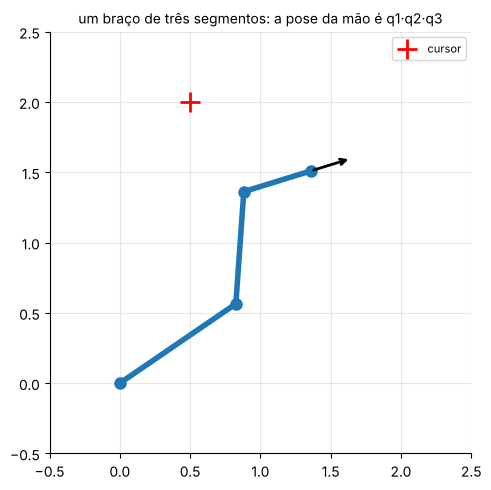

In [5]:
ELLS = [1.0, 0.8, 0.5]

def cadeia(thetas, ells=ELLS):
    """Poses no mundo de cada junta e da mão."""
    q, poses = pose(0.0, 0j), [pose(0.0, 0j)]
    for th, l in zip(thetas, ells):
        q = q * pose(th, 0j) * pose(0.0, l + 0j)
        poses.append(q)
    return poses

thetas = [0.6, 0.9, -1.2]
poses = cadeia(thetas)
mao = poses[-1]
pos_formula = sum(l * np.exp(1j * np.sum(thetas[:k + 1])) for k, l in enumerate(ELLS))
print(f"mão em {translacao(mao):.4f}, apontando para {np.degrees(angulo(mao)):.1f}°")
confere("produto da cadeia = soma de vetores girados", translacao(mao), pos_formula, tol=1e-14)
confere("orientação da mão = θ1 + θ2 + θ3", angulo(mao), sum(thetas), tol=1e-14)

cursor = 0.5 + 2.0j
no_ref_mao = aplica(mao.conj(), cursor)
print(f"o cursor {cursor} visto da mão: {no_ref_mao:.4f}")
confere("voltar ao mundo devolve o cursor", aplica(mao, no_ref_mao), cursor, tol=1e-14)

fig, ax = plt.subplots(figsize=(5.5, 5))
pts = [translacao(p) for p in poses]
ax.plot([p.real for p in pts], [p.imag for p in pts], "-o", lw=4, ms=8, color="tab:blue")
ax.plot(cursor.real, cursor.imag, "r+", ms=14, mew=2, label="cursor")
ponta = translacao(mao); nariz = ponta + 0.3 * np.exp(1j * angulo(mao))
ax.annotate("", xy=(nariz.real, nariz.imag), xytext=(ponta.real, ponta.imag), arrowprops={"arrowstyle": "->", "lw": 2})
ax.set_aspect("equal"); ax.set_xlim(-0.5, 2.5); ax.set_ylim(-0.5, 2.5); ax.legend(fontsize=8)
ax.set_title("um braço de três segmentos: a pose da mão é q1·q2·q3", fontsize=10)
plt.tight_layout(); plt.show()

---

## 5. Exp e Log

**A velocidade de uma pose.** Um objeto que gira com velocidade angular $\omega$ e anda com velocidade $v$ (complexa) **no próprio referencial**, por uma unidade de tempo, descreve um **arco de círculo** (ou um segmento de reta, se $\omega=0$). O resultado é a $\mathrm{Exp}$ do domínio:

$$\mathrm{Exp}(\omega,v)=\mathrm{pose}\Big(\omega,\ v\,\frac{e^{i\omega}-1}{i\omega}\Big).$$

O fator $\dfrac{e^{i\omega}-1}{i\omega}$ é a média de $e^{i\omega s}$ para $s$ entre 0 e 1: a direção média do movimento ao longo do arco. A $\mathrm{Log}$ faz o caminho inverso: dada uma pose, qual velocidade constante a produz em uma unidade de tempo.

**Uma fórmula que perde dígitos.** Para $\omega$ pequeno, $e^{i\omega}-1$ é a diferença de dois números quase iguais (o cancelamento do notebook I(a)), e a divisão por $\omega$ amplifica o erro. A saída é reescrever: $\dfrac{e^{i\omega}-1}{i\omega}=e^{i\omega/2}\,\dfrac{\sin(\omega/2)}{\omega/2}$, sem subtração. A função $\mathrm{sinc}$ do NumPy calcula $\sin(x)/x$ sem perder dígitos perto de zero. Toda biblioteca de grupos de Lie precisa desse cuidado.

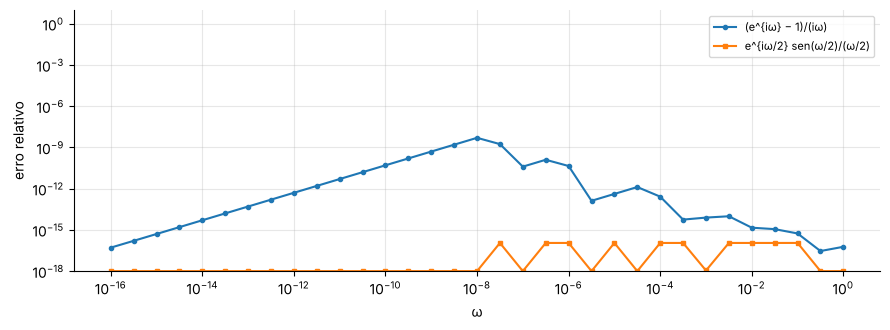

ω = 1e-12: fórmula ingênua erra 2.6e-13;  forma estável erra 1.1e-16
OK   a forma estável acerta em todo o intervalo:  diferença máxima = 1.11e-16
OK   Log(Exp(ω = 0.8, v = (1.5+0.2j))) = (ω, v):  diferença máxima = 6.80e-16
OK   Log(Exp(ω = 1e-09, v = (2+0j))) = (ω, v):  diferença máxima = 8.27e-17
OK   Log(Exp(ω = -2.5, v = (0.3-1j))) = (ω, v):  diferença máxima = 1.11e-16


In [6]:
import mpmath as mp
mp.mp.dps = 40
ws = np.logspace(-16, 0, 33)
ingenua = (np.exp(1j * ws) - 1) / (1j * ws)
estavel = np.exp(0.5j * ws) * sinc(ws / 2)
ref = np.array([complex((mp.expj(mp.mpf(w)) - 1) / (1j * mp.mpf(w))) for w in ws])
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.loglog(ws, np.abs(ingenua - ref) / np.abs(ref) + 1e-18, "o-", ms=3, label="(e^{iω} − 1)/(iω)")
ax.loglog(ws, np.abs(estavel - ref) / np.abs(ref) + 1e-18, "s-", ms=3, label="e^{iω/2} sen(ω/2)/(ω/2)")
ax.set_xlabel("ω"); ax.set_ylabel("erro relativo"); ax.legend(fontsize=8); ax.set_ylim(1e-18, 10)
plt.tight_layout(); plt.show()
print(f"ω = 1e-12: fórmula ingênua erra {abs(ingenua[24] - ref[24]) / abs(ref[24]):.1e};  forma estável erra {abs(estavel[24] - ref[24]) / abs(ref[24]):.1e}")
confere("a forma estável acerta em todo o intervalo", np.max(np.abs(estavel - ref) / np.abs(ref)), 0, tol=3e-16)

for xi in [(0.8, 1.5 + 0.2j), (1e-9, 2.0 + 0j), (-2.5, 0.3 - 1j)]:
    w_, v_ = Log(Exp(*xi))
    confere(f"Log(Exp(ω = {xi[0]:g}, v = {xi[1]})) = (ω, v)", [w_, v_], list(xi), tol=1e-14)

### O centro instantâneo de rotação

Todo movimento rígido do plano que não é uma translação pura é uma **rotação em torno de algum ponto fixo** $c$ (o teorema de Chasles, no plano). O ponto fixo satisfaz $e^{i\theta}c+t=c$, e então

$$c=\frac{t}{1-e^{i\theta}} .$$

Uma aplicação: duas fotos de uma porta, com dois pontos marcados nela. Das duas posições dos dois pontos saem o ângulo e a translação (o segmento entre os pontos gira de $\theta$), e da fórmula sai a **dobradiça**. O denominador $1-e^{i\theta}$ tende a zero com $\theta$: para giros pequenos, a dobradiça vai para longe (no limite, a translação pura, "rotação em torno de um ponto no infinito"), e o problema fica mal condicionado. A célula mede isso com pontos ruidosos.

In [7]:
dobradica = 1.0 + 2.0j
marcas = np.array([1.3 + 2.0j, 1.9 + 2.0j])               # dois pontos na porta fechada

def localiza_dobradica(antes, depois):
    th = np.angle((depois[1] - depois[0]) / (antes[1] - antes[0]))
    t = depois[0] - np.exp(1j * th) * antes[0]
    return t / (1 - np.exp(1j * th))

print(" abertura   erro da dobradiça (marcas com ruído de 1 mm, mediana de 2000 sorteios)")
for graus in [90, 30, 10, 3, 1]:
    th = np.radians(graus)
    depois = dobradica + np.exp(1j * th) * (marcas - dobradica)
    confere(f"  sem ruído, acha a dobradiça ({graus}°)", localiza_dobradica(marcas, depois), dobradica, tol=1e-12)
    erros = [abs(localiza_dobradica(marcas + 1e-3 * (rng.standard_normal(2) + 1j * rng.standard_normal(2)),
                                    depois + 1e-3 * (rng.standard_normal(2) + 1j * rng.standard_normal(2))) - dobradica) for _ in range(2000)]
    print(f"   {graus:4d}°      {1000 * np.median(erros):8.1f} mm")

 abertura   erro da dobradiça (marcas com ruído de 1 mm, mediana de 2000 sorteios)
OK     sem ruído, acha a dobradiça (90°):  diferença máxima = 2.22e-16
     90°           1.5 mm
OK     sem ruído, acha a dobradiça (30°):  diferença máxima = 6.28e-16
     30°           4.2 mm
OK     sem ruído, acha a dobradiça (10°):  diferença máxima = 1.37e-15
     10°          12.4 mm
OK     sem ruído, acha a dobradiça (3°):  diferença máxima = 4.97e-15
      3°          41.5 mm
OK     sem ruído, acha a dobradiça (1°):  diferença máxima = 4.97e-16
      1°         118.2 mm


**Leitura.** Com a porta aberta 90°, um milímetro de erro nas marcas vira poucos milímetros na dobradiça. Com 1°, vira mais de dez centímetros: o erro cresce como $1/\theta$, porque o denominador $\lvert1-e^{i\theta}\rvert\approx\theta$ tende a zero. É o mesmo recado das retas quase paralelas do notebook II(b): a informação sobre o centro está na rotação, e uma rotação pequena tem pouca.

---

## 6. Interpolar poses: o arco e a reta

Para animar um objeto de uma pose $q_0$ a uma pose $q_1$ (um personagem, uma câmera), há dois caminhos naturais:
- **interpolar as coordenadas:** ângulo e posição separadamente, em linha reta. A posição anda em linha reta enquanto o ângulo gira;
- **interpolar no grupo:** $q(s)=q_0\,\mathrm{Exp}\big(s\,\mathrm{Log}(q_0^{-1}q_1)\big)$, com $s$ de 0 a 1. É o movimento com velocidade constante **no referencial do objeto** que leva de $q_0$ a $q_1$: um arco de círculo. Para dual quaternions, a mesma ideia se chama ScLERP (*screw linear interpolation*).

Os dois caminhos terminam no mesmo lugar e passam por lugares diferentes.

OK   o arco termina em q1:  diferença máxima = 6.66e-16
OK   no arco, cada passo é o mesmo no referencial do objeto:  diferença máxima = 1.14e-15


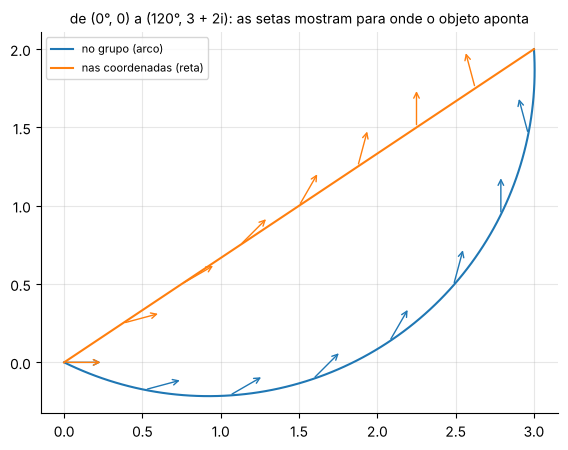

In [8]:
q0, q1 = pose(0.0, 0j), pose(np.radians(120), 3 + 2j)
w01, v01 = Log(q0.conj() * q1)
ss = np.linspace(0, 1, 9)
arco = [q0 * Exp(s * w01, s * v01) for s in ss]
reta = [pose(s * np.radians(120), s * (3 + 2j)) for s in ss]
confere("o arco termina em q1", [angulo(arco[-1]), translacao(arco[-1])], [angulo(q1), translacao(q1)], tol=1e-14)

# no arco, a velocidade no referencial do objeto é constante e aponta sempre na mesma direção do corpo
v_corpo = [aplica(arco[k].conj(), translacao(arco[k + 1])) for k in range(len(ss) - 1)]
confere("no arco, cada passo é o mesmo no referencial do objeto", np.array(v_corpo), np.full(len(v_corpo), v_corpo[0]), tol=1e-13)

fig, ax = plt.subplots(figsize=(7, 4.6))
sf = np.linspace(0, 1, 100)
finos = {"no grupo (arco)": [q0 * Exp(s * w01, s * v01) for s in sf], "nas coordenadas (reta)": [pose(s * np.radians(120), s * (3 + 2j)) for s in sf]}
for nome, cam, cor in [("no grupo (arco)", arco, "tab:blue"), ("nas coordenadas (reta)", reta, "tab:orange")]:
    pts = np.array([translacao(q) for q in finos[nome]])
    ax.plot(pts.real, pts.imag, "-", color=cor, label=nome)
    for q in cam:
        p = translacao(q); d = 0.25 * np.exp(1j * angulo(q))
        ax.annotate("", xy=(p.real + d.real, p.imag + d.imag), xytext=(p.real, p.imag), arrowprops={"arrowstyle": "->", "color": cor})
ax.set_aspect("equal"); ax.legend(fontsize=8); ax.set_title("de (0°, 0) a (120°, 3 + 2i): as setas mostram para onde o objeto aponta", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** No arco (azul), o caminho é um arco de círculo e a seta faz sempre o **mesmo ângulo** com ele: no referencial do objeto, o movimento é sempre igual (a segunda conferência). Na reta (laranja), o ângulo entre a seta e o caminho muda o tempo todo: no começo o objeto anda de lado, no fim anda quase de costas para a direção em que gira. Um carro, que só anda para onde aponta, segue arcos em que esse ângulo é zero; para chegar a uma pose qualquer, em geral precisa de mais de um arco (é o problema das manobras de estacionamento).

---

## 7. Deformar um personagem 2D (*skinning*)

Um personagem animado é desenhado sobre um **esqueleto**: cada "osso" tem uma pose, e cada ponto do desenho segue uma **mistura** das poses dos ossos vizinhos, com pesos que variam suavemente perto das juntas. A forma mais simples de misturar é somar as **matrizes** das poses com os pesos (*linear blend skinning*). Ela tem um defeito famoso: numa junta muito dobrada, a mistura de duas rotações não é uma rotação, e o desenho **encolhe** perto da junta (o defeito do "papel de bala" ou do "cotovelo de borracha").

Os dual-complexos foram propostos exatamente para isso: misturar os **dual-complexos** das poses com os pesos e normalizar o resultado, $q=\dfrac{\sum w_kq_k}{\lvert\sum w_ka_k\rvert}$. O resultado é sempre um dual-complexo unitário, isto é, uma pose rígida. A célula dobra um tubo de 4 por 0,6 em 150° na metade e mede a espessura do tubo na junta.

espessura na junta, original       : 0.600
espessura na junta, matrizes       : 0.155
espessura na junta, dual-complexos : 0.600
OK   os dual-complexos preservam a espessura na junta:  diferença máxima = 1.11e-16


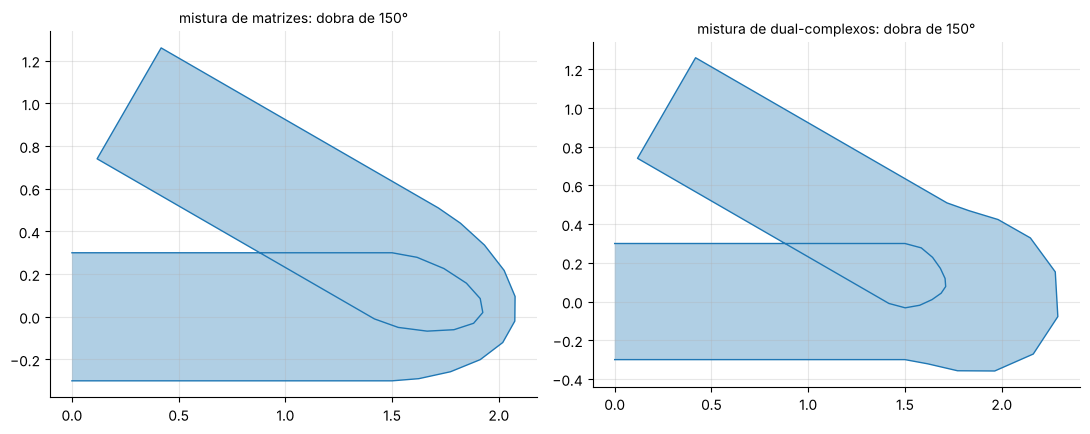

In [9]:
def tubo(n=41, comprimento=4.0, espessura=0.6):
    xs = np.linspace(0, comprimento, n)
    return np.r_[xs + 0.5j * espessura, xs[::-1] - 0.5j * espessura]

def pesos(x, junta=2.0, largura=1.0):
    s = np.clip((x - junta + largura / 2) / largura, 0, 1)
    return 3 * s**2 - 2 * s**3                          # de 0 a 1, suave, em volta da junta

def matriz(q):
    th, t = angulo(q), translacao(q)
    return np.array([[np.cos(th), -np.sin(th), t.real], [np.sin(th), np.cos(th), t.imag], [0, 0, 1]])

dobra = np.radians(150)
osso1 = pose(0.0, 0j)
osso2 = pose(0.0, 2.0 + 0j) * pose(dobra, 0j) * pose(0.0, -2.0 + 0j)     # gira 150° em torno da junta em x = 2
P = tubo(); W = pesos(P.real)

lbs = []
for p, w in zip(P, W):
    Mm = (1 - w) * matriz(osso1) + w * matriz(osso2)
    v = Mm @ np.array([p.real, p.imag, 1.0]); lbs.append(v[0] + 1j * v[1])
lbs = np.array(lbs)

dlb = []
for p, w in zip(P, W):
    q2 = osso2 if (osso1.a0 * osso2.a0 + osso1.a1 * osso2.a1) >= 0 else osso2 * (-1.0)   # mesmo "lado" do duplo recobrimento
    qm = osso1 * (1 - w) + q2 * w
    qm = qm * (1 / np.sqrt(qm.norma2()))
    dlb.append(aplica(qm, p))
dlb = np.array(dlb)

n = len(P) // 2
meio = np.argmin(np.abs(P[:n].real - 2.0))            # o ponto de cima na junta e o seu par de baixo
par = len(P) - 1 - meio
esp = {"original": abs(P[meio] - P[par]), "matrizes": abs(lbs[meio] - lbs[par]), "dual-complexos": abs(dlb[meio] - dlb[par])}
for k, v in esp.items():
    print(f"espessura na junta, {k:15s}: {v:.3f}")
confere("os dual-complexos preservam a espessura na junta", esp["dual-complexos"], esp["original"], tol=1e-12)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for a_, pts, tit in zip(ax, [lbs, dlb], ["mistura de matrizes", "mistura de dual-complexos"]):
    a_.fill(pts.real, pts.imag, alpha=.35); a_.plot(pts.real, pts.imag, lw=1)
    a_.plot([P[meio].real], [P[meio].imag], "k.", alpha=0); a_.set_aspect("equal"); a_.set_title(f"{tit}: dobra de 150°", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** Com a mistura de matrizes, a espessura na junta cai para uma fração da original: no ponto em que os pesos são meio a meio, a "rotação" média de 0° e 150° é uma matriz que encolhe tudo por $\cos75°\approx0{,}26$. Com dual-complexos, a mistura é sempre uma pose rígida (girar 75° em torno da junta, no ponto do meio), e a espessura se mantém exatamente. É o mesmo argumento dos dual quaternions na animação 3D (Kavan e outros, 2007), que os estúdios adotaram.

---

## 8. Poses exatas com inteiros gaussianos

O notebook IV(a) mostrou que, em `float`, compor rotações faz o módulo escorregar. Há rotações que se podem fazer **sem nenhum erro**: as de seno e cosseno racionais, que vêm das ternas pitagóricas. Por exemplo, $3^2+4^2=5^2$ dá a rotação $e^{i\theta}=\tfrac{3+4i}{5}$, de $\theta\approx53{,}13°$.

No dual-complexo, o ângulo aparece pela metade: $r=e^{i\theta/2}=\tfrac{2+i}{\sqrt5}$, que não é racional. A saída é não normalizar: a fórmula $t=2ba/\lvert a\rvert^2$ (seção 3) vale para qualquer $a\neq0$, e o produto de dual-complexos não unitários continua compondo as poses (a norma é multiplicativa). Com $a=2+i$ (um **inteiro gaussiano**) e $b$ de coordenadas racionais, toda a conta é feita em `Fraction`, sem arredondamento.

A célula compõe 200 vezes a mesma pose (girar 53,13° e andar $(1,\tfrac12)$) de três maneiras: exata, em `float` com dual-complexos, e em `float` somando ângulos.

In [10]:
F_ = Fraction
t_passo = F_(1), F_(1, 2)
# pose exata: a = 2 + i, b = t ā / 2 (o mesmo que t r̄ / 2 a menos da escala |a|)
a_ex = (F_(2), F_(1))
b_ex = ((t_passo[0] * a_ex[0] + t_passo[1] * a_ex[1]) / 2, (t_passo[1] * a_ex[0] - t_passo[0] * a_ex[1]) / 2)
q_exato_passo = DC(a_ex[0], a_ex[1], b_ex[0], b_ex[1])
q_float_passo = pose(np.angle((3 + 4j) / 5), 1 + 0.5j)

def translacao_exata(q):
    n2 = q.norma2()
    br = 2 * (q.b0 * q.a0 - q.b1 * q.a1) / n2; bi = 2 * (q.b0 * q.a1 + q.b1 * q.a0) / n2
    return br, bi

confere("o passo exato e o passo em float são a mesma pose",
        complex(*map(float, translacao_exata(q_exato_passo))), translacao(q_float_passo), tol=1e-15)

q_ex, q_fl = DC(F_(1), F_(0), F_(0), F_(0)), pose(0.0, 0j)
th_soma, t_soma = 0.0, 0j
for k in range(200):
    q_ex = q_ex * q_exato_passo
    q_fl = q_fl * q_float_passo
    t_soma = t_soma + np.exp(1j * th_soma) * (1 + 0.5j); th_soma += np.angle((3 + 4j) / 5)
t_ex = complex(*map(float, translacao_exata(q_ex)))
print(f"depois de 200 passos: translação exata  = {t_ex:.15f}")
print(f"   dual-complexo em float: erro {abs(translacao(q_fl) - t_ex):.2e};  |a| − 1 = {np.sqrt(q_fl.norma2()) - 1:+.2e}")
print(f"   somando ângulos:        erro {abs(t_soma - t_ex):.2e}")
print(f"tamanho dos números exatos: a parte real de a tem {len(str(q_ex.a0))} dígitos")

OK   o passo exato e o passo em float são a mesma pose:  diferença máxima = 1.11e-16
depois de 200 passos: translação exata  = -0.131104728447000+2.493105607009653j
   dual-complexo em float: erro 2.61e-14;  |a| − 1 = -8.88e-16
   somando ângulos:        erro 3.18e-13
tamanho dos números exatos: a parte real de a tem 69 dígitos


**Leitura.** A composição exata não erra nada, por construção; as duas em `float` erram pouco depois de 200 passos, mas erram, e o erro cresce com o número de passos. O preço da exatidão aparece na última linha: os inteiros crescem ($\lvert a\rvert^2$ é multiplicado por 5 a cada passo, e depois de 200 passos as partes de $a$ têm dezenas de dígitos; as frações de $b$, ainda mais). É o compromisso de sempre entre `float` e aritmética exata (notebook I(a)): exatidão total, custo crescente. Em geometria computacional, rotações racionais são usadas justamente para girar figuras sem estragar os testes de orientação do notebook II(a).

> **Nota: a órbita não se fecha.** O ângulo $\arctan(4/3)$ não é uma fração racional de $\pi$ (um teorema de Niven), e por isso a rotação $\tfrac{3+4i}{5}$, repetida, nunca volta exatamente ao começo: os pontos se espalham pelo círculo sem se repetir.

---

## 9. A interface de domínio para $SE(2)$

| operação | significado | com dual-complexos |
|---|---|---|
| `compoe(g, h)` | fazer $g$, depois $h$ (no referencial de $g$) | $q_gq_h$ |
| `inverso(g)` | desfazer | $q_g^*$ |
| `identidade` | ficar parado | $1+0\varepsilon$ |
| `Exp(ξ)` | velocidade $\xi=(\omega,v_x,v_y)$ no corpo por uma unidade de tempo | o arco da seção 5 |
| `Log(g)` | a velocidade constante que produz $g$ | idem, ao contrário |
| $x\boxplus\delta$ | perturbar $x$ por $\delta$ **no referencial do objeto** | $q_x\,\mathrm{Exp}(\delta)$ |

**A ordem agora importa.** Em $SE(2)$, $q\,\mathrm{Exp}(\delta)$ (perturbar no referencial do objeto) e $\mathrm{Exp}(\delta)\,q$ (perturbar no referencial do mundo) são diferentes. As duas convenções são usadas, e o notebook V(d) compara filtros de Kalman construídos com cada uma. Os testes abaixo são os mesmos dos domínios anteriores, e mais um: a não comutatividade.

In [11]:
class DominioSE2:
    """Domínio V: poses do plano como dual-complexos unitários."""
    nome = "SE(2) (dual-complexos)"
    dim = 3
    identidade = pose(0.0, 0j)
    def compoe(self, g, h): return g * h
    def inverso(self, g):   return g.conj()
    def Exp(self, xi):      return Exp(xi[0], xi[1] + 1j * xi[2])
    def Log(self, g):
        w, v = Log(g); return np.array([w, v.real, v.imag])
    def mais(self, x, d):   return self.compoe(x, self.Exp(d))
    def menos(self, y, x):  return self.Log(self.compoe(self.inverso(x), y))

def testa_dominio(D, amostra, tol=1e-12):
    g, h, k = amostra(), amostra(), amostra()
    print(f"domínio {D.nome}")
    confere("  associatividade da composição", D.menos(D.compoe(D.compoe(g, h), k), D.compoe(g, D.compoe(h, k))), 0, tol)
    confere("  identidade", D.menos(D.compoe(g, D.identidade), g), 0, tol)
    confere("  inverso", D.menos(D.compoe(g, D.inverso(g)), D.identidade), 0, tol)
    d = D.Log(amostra()) * 0.3
    confere("  Log(Exp(δ)) = δ", D.Log(D.Exp(d)), d, tol)
    confere("  (x ⊞ δ) ⊟ x = δ", D.menos(D.mais(g, d), g), d, tol)
    confere("  x ⊞ (y ⊟ x) = y", D.menos(D.mais(g, D.menos(h, g)), h), 0, tol)

S = DominioSE2()
amostra = lambda: pose(rng.uniform(-np.pi, np.pi), complex(*rng.normal(scale=3, size=2)))
testa_dominio(S, amostra)
g, h = amostra(), amostra()
dif = S.menos(S.compoe(g, h), S.compoe(h, g))
print("\ng·h ⊟ h·g =", dif)
confere("o grupo não é comutativo", np.linalg.norm(dif) > 0.1, True)
d = np.array([0.3, 0.5, -0.2])
print("x·Exp(δ) ⊟ Exp(δ)·x =", S.menos(S.compoe(g, S.Exp(d)), S.compoe(S.Exp(d), g)), " ← perturbar no corpo ≠ perturbar no mundo")

domínio SE(2) (dual-complexos)
OK     associatividade da composição:  diferença máxima = 1.33e-15
OK     identidade:  diferença máxima = 0.00e+00
OK     inverso:  diferença máxima = 0.00e+00
OK     Log(Exp(δ)) = δ:  diferença máxima = 5.55e-17
OK     (x ⊞ δ) ⊟ x = δ:  diferença máxima = 7.22e-16
OK     x ⊞ (y ⊟ x) = y:  diferença máxima = 1.33e-15

g·h ⊟ h·g = [ 0.       -6.461986  2.042203]
OK   o grupo não é comutativo:  diferença máxima = 0.00e+00
x·Exp(δ) ⊟ Exp(δ)·x = [ 0.        0.50015  -1.080128]  ← perturbar no corpo ≠ perturbar no mundo


**Para pensar.** Em todos os domínios anteriores, compor era somar, ou multiplicar números que comutam. Aqui, a composição de dual-complexos é a primeira operação da série em que $gh\neq hg$. Tudo que dependia da comutatividade precisa ser revisto: o RKMK (notebook V(c)) ganha um termo de correção, o colchete de Lie; o filtro de Kalman (notebook V(d)) passa a ter duas maneiras diferentes de definir o erro.

---

## 10. Exercícios

1. **Outra convenção.** Refaça a álgebra com a regra $\varepsilon z=\bar z\varepsilon$ e a parte dual escrita à direita ($a+\varepsilon b$). Qual é a codificação de uma pose que faz o produto compor? (O teste da seção 3 é a maneira mais rápida de descobrir.)
2. **Cinemática direta de um braço de $n$ segmentos.** Generalize a seção 4 para $n$ segmentos e meça o custo (em multiplicações reais) de calcular a pose da mão com dual-complexos e com matrizes $3\times3$.
3. **Interpolação com os dois representantes.** Na seção 6, troque $q_1$ por $-q_1$ (a mesma pose). O arco muda? E se a interpolação fosse feita misturando $(1-s)q_0+s\,q_1$ e normalizando, como no *skinning*?
4. ***Skinning* com três ossos.** Faça um tubo com duas juntas e pesos que misturam três ossos em parte do tubo. A mistura de dual-complexos continua preservando a espessura?
5. **Mais ternas pitagóricas.** Use $5^2+12^2=13^2$ para outra rotação exata. Qual é o inteiro gaussiano $a$ que a representa no dual-complexo? (Dica: procure $a$ com $a^2=5+12i$.)